# 09 — SVM, reconhecimento de caracteres e classificação visual

**EP · Data Science Knowledge Base | Análise e Classificação de Imagens | Notebook 09/16**

**Pré-requisitos:** Python, NumPy e fundamentos de visualização; consulte os capítulos anteriores quando necessário.

**Escopo de validação:** As células principais usam dados sintéticos ou conjuntos fornecidos pelas bibliotecas. Dependências adicionais só são necessárias nos laboratórios explicitamente opcionais.

---

> **Biblioteca pessoal de Ciência de Dados** · Análise e Classificação de Imagens · Capítulo 09/16

> **Execução:** células principais executadas localmente no JupyterLab em 14/11/2026, conforme confirmação do autor.


### Materiais complementares

- [Guia Técnico](./reference_materials/09_svm_ocr_classificacao.pdf)
- [Cheat Sheet](./cheat_sheets/cheat_sheet_svm_ocr_classificacao.pdf)


## Como estudar este capítulo

1. Leia os fundamentos e consulte o Guia Técnico correspondente.
2. Reinicie o kernel e execute as células obrigatórias na sequência.
3. Confira tabelas, visualizações, saídas e limitações descritas no notebook.
4. Resolva o exercício antes de consultar a solução; execute laboratórios opcionais apenas em ambiente compatível.

**Pré-requisitos transversais:** Programação Python (01), visualização de dados (02), Estatística (03), Machine Learning (05) e Deep Learning (07), conforme o capítulo.


## Objetivos de aprendizagem

Treinar baseline de classificação visual com separação correta e matriz de confusão.

Ao concluir, você deverá ser capaz de **explicar a técnica**, **executar o exemplo**, **interpretar limitações** e **justificar escolhas de avaliação**.

## Fundamentos conceituais

Reconhecimento de caracteres em imagem exige segmentação/alinhamento e classificador, ou sistemas de OCR fim a fim. SVM busca margem máxima com penalização de erros e pode consumir descritores como HOG. Comparar pixels achatados e HOG; definir validação antes de seleção. Não confundir OCR de caracteres isolados com leitura de documentos.

### Conceito matemático

$$\min_{w,b}\frac12\|w\|^2+C\sum_i\xi_i$$

A fórmula expressa o mecanismo principal do capítulo. Identifique unidades, dimensões e hipóteses antes de aplicar uma implementação.

## Experimento 1 — construção e medidas

Execute em kernel limpo. Exemplos usam datasets de bibliotecas instaláveis e não requerem download de arquivos externos.

In [1]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,confusion_matrix
D=load_digits();a,b,ya,yb=train_test_split(D.data,D.target,test_size=.25,random_state=42,stratify=D.target)
clf=make_pipeline(StandardScaler(),SVC(kernel='rbf',C=2,gamma='scale')).fit(a,ya)
pred=clf.predict(b)
print('accuracy dígitos:',round(accuracy_score(yb,pred),3),'confusion shape:',confusion_matrix(yb,pred).shape)

accuracy dígitos: 0.98 confusion shape: (10, 10)


## Experimento 2 — visualização, comparação ou validação

Observe não apenas o valor obtido, mas o que o experimento **realmente demonstra**.

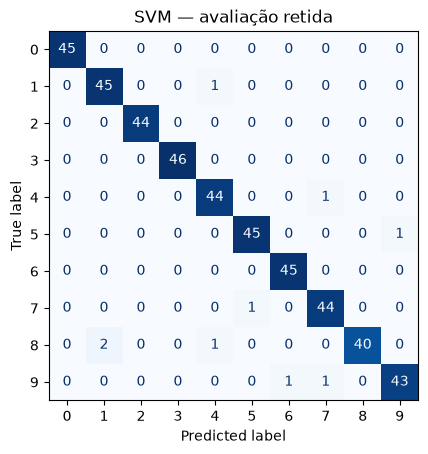

In [2]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(yb,pred,cmap='Blues',colorbar=False,values_format='d')
plt.title('SVM — avaliação retida');plt.show()

## Interpretação técnica

Erros entre dígitos visualmente semelhantes devem ser examinados individualmente.

### Conexão com o acervo

Em vez de repetir capítulos de SVM, PCA, métricas e backpropagation, este notebook concentra a aplicação e limitações **em imagens**. Revisite as Disciplinas 05 e 07 para demonstrações matemáticas mais extensas.

## Exercício resolvido

**Problema:** Por que separar treino e teste antes da seleção de hiperparâmetros?

**Resolução comentada:** Para evitar que o teste influencie as decisões de modelagem e gere desempenho otimista.

**Para praticar:** modifique um parâmetro do exemplo, registre a hipótese antes de executar e compare resultado, qualidade visual e custo computacional.

## Erros comuns e limitações

Para OCR real, avaliar também sequência de caracteres e erros de transcrição por documento.

- Nunca ajustar parâmetros em cima do conjunto de teste final.
- Não confundir demonstração com validação científica completa.
- Documentar versões, fontes de dados e condições de execução.
- Não redistribuir fotografias de rostos ou datasets históricos sem licença e autorização.

## Consulta rápida

- **Pergunta-chave:** Treinar baseline de classificação visual com separação correta e matriz de confusão.
- **Mecanismo:** Reconhecimento de caracteres em imagem exige segmentação/alinhamento e classificador, ou sistemas de OCR fim a fim.
- **Equação:** $\min_{w,b}\frac12\|w\|^2+C\sum_i\xi_i$
- **Verificação:** interpretar formato dos dados, hipótese e saída antes de utilizar em um projeto.

### Referências de estudo

- Apresentações originais da disciplina (PDF consolidado).
- Documentação: [scikit-image](https://scikit-image.org/docs/stable/), [OpenCV](https://docs.opencv.org/4.x/), [scikit-learn](https://scikit-learn.org/stable/), conforme o capítulo.
- Para CNNs: [Keras](https://keras.io/).

## Aprofundamento v2 — auditoria e aplicação

**Ponto de atenção deste capítulo:** divisão por imagem/pessoa. Este complemento não substitui as seções e exemplos anteriores.

**Verificação conceitual.** Explique, com suas palavras, em qual etapa do fluxo de trabalho o tema **divisão por imagem/pessoa** pode produzir conclusões enganosas. Indique um indicador observável, um teste mínimo e uma limitação do procedimento.

**Exercício de extensão.** Reproduza o experimento central deste notebook alterando **um parâmetro por vez**. Compare com uma linha de base simples, reporte a variação da métrica pertinente e justifique o resultado. Quando houver treino/teste, qualquer etapa que aprenda parâmetros deve usar apenas o treino.

**Checklist de conclusão:** (1) entradas identificadas; (2) sementes registradas; (3) saídas interpretadas; (4) premissas explicitadas; (5) dados originais não sobrescritos.


### Exercício resolvido — protocolo mínimo de validação

**Enunciado.** Proponha uma comparação para **divisão por imagem/pessoa** sem contaminar a avaliação.

**Solução orientadora.** Defina uma hipótese falsificável, escolha um baseline simples, fixe uma divisão adequada ao problema, altere uma única decisão metodológica e compare métricas no conjunto reservado. Não transforme exemplos sintéticos em conclusões sobre populações reais. Documente a configuração e os casos de falha. Quando o tema não envolver predição, substitua o baseline por uma implementação de referência e compare correção, cobertura e custo.
